## Modelo 2 · SVR para estimar propiedades de galaxias

Imágenes de DESI Legacy Imaging Surveys, características visuales fijas y redshift

Instituto Tecnológico y de Estudios Superiores de Monterrey (ITESM) · Equipo 24

José Florencio Maguey Peralta — A01796727  
Erick Alberto Bustos Cruz — A01378966  
Luz Copelia Minutti Pérez — A01796921

En este notebook construimos nuestro segundo candidato mediante regresión de vectores de soporte, SVR, con kernel RBF. Conservamos las galaxias, etiquetas y particiones de la ejecución A–G. Estimamos `log_mstar`, `log_sfr` y `d4000`, manteniendo las definiciones del catálogo neuronal y sin sustituir la masa por una referencia de otro catálogo.

Para utilizar las imágenes con SVR las convertimos primero en un vector de características. Empleamos una ResNet50 con pesos de ImageNet1K V1, congelada y sin ajuste con las etiquetas de nuestras galaxias. Después reducimos la dimensión visual con PCA, incorporamos el redshift y entrenamos un SVR por propiedad. Esta cadena combina extracción de características y regresión; no combina predicciones de varias redes para producir un ensamble. Los tres SVR corresponden a objetivos distintos y representan un único candidato metodológico en la comparación de algoritmos.

Elegimos los pesos originales de ImageNet para que este candidato no dependa del extractor ajustado de la variante E. Por esa razón utilizamos las composiciones RGB de A–G y la normalización de ImageNet. La comparación con E, que utiliza GRZ y ajuste fino, evalúa sistemas completos: no aísla exclusivamente el cambio de la cabeza de regresión. Tampoco presentamos este modelo como SVR aplicado directamente a píxeles ni como una alternativa completamente ajena a las características de una CNN.

Preparamos aquí una configuración inicial, con decisiones fijadas antes de ejecutarla. Reservamos la búsqueda de hiperparámetros para la etapa posterior a comparar seis candidatos y seleccionar los dos mejores. Las celdas de resultados y conclusión se completan con las métricas que calculemos al ejecutar; este archivo no contiene resultados astronómicos simulados.

## Declaración de IA

Utilizamos inteligencia artificial, a través de ChatGPT con el modelo GPT-6, como apoyo para construir el código a partir de un planteamiento general. Posteriormente, revisamos y realizamos ajustes técnicos siguiendo las indicaciones de nuestros asesores en astronomía, el Dr. Héctor Hernández Toledo y el Dr. José Antonio Vázquez Mata. Debido al nivel de especialización del problema, fue necesario adaptar el código al significado físico de las variables, las características de los datos observacionales y las correcciones propias de la disciplina. De esta manera, el uso de IA se complementó con la revisión del equipo y la orientación científica de los asesores.


## 1 · Entorno y archivos necesarios

Leemos `muestra_lista.csv`, `definicion_muestra.json`, `estadisticos_Train.json` y `configuracion.json`, además de los archivos RGB y sus sellos. Para comparar con el candidato neuronal usamos también `seleccion_cerrada.json`, `fuentes_comparacion_A_G.json` y las predicciones de Validation. Solo escribimos en una carpeta nueva de SVR.


In [1]:
import os
import sys
import json
import hashlib
import time
import platform
import warnings
import zipfile
import io
import importlib.util
from pathlib import Path
from datetime import datetime, timezone

requeridos = ['numpy', 'pandas', 'sklearn', 'joblib', 'matplotlib', 'threadpoolctl']
faltantes = [nombre for nombre in requeridos if importlib.util.find_spec(nombre) is None]
if faltantes:
    raise RuntimeError('Faltan bibliotecas en este kernel: ' + ', '.join(faltantes)
                       + '. Instálalas en ' + sys.executable + ' antes de continuar.')
import numpy as np
import pandas as pd
import sklearn
import joblib
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVR
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, FileLink


## 2 · Configuración inicial y razones de las elecciones

Fijamos los siguientes valores para construir un candidato evaluable. 

| Parámetro | Valor inicial | Razón de la elección |
|---|---|---|
| Extractor | ResNet50 ImageNet1K V1 congelada | Reutilizamos características visuales sin entrenar otra CNN ni depender del modelo E. |
| Representación | RGB Lupton de A–G, 300 × 300 | Aprovechamos las imágenes ya preparadas y conservamos tres canales en el orden RGB del preentrenamiento. |
| Componentes de PCA | 128 | Reducimos las 2048 características para contener el costo del SVR y limitar redundancia. Medimos la varianza retenida; no suponemos que 128 conserve toda la información predictiva. |
| Redshift | Sí, como entrada separada | Conservamos esta información sin mezclarla dentro de la reducción visual. |
| Kernel | RBF | Permitimos relaciones no lineales entre las características y las propiedades. |
| C | 10 | Utilizamos una penalización inicial de errores sobre etiquetas estandarizadas; su conveniencia queda pendiente de evaluación y eventual ajuste. |
| Epsilon | 0.1 | Establecemos una banda sin penalización de 0.1 desviaciones de Train por etiqueta; no equivale a una incertidumbre física conocida. |
| Gamma | `scale` | Definimos la escala del kernel a partir de la dimensión y varianza de las entradas ya preparadas. |
| Tolerancia del solver | 0.001 | Utilizamos una tolerancia numérica inicial y comprobamos la convergencia. |
| Máximo de iteraciones | −1, sin límite fijo | Evitamos aceptar un ajuste detenido por un límite arbitrario; el tiempo puede variar por propiedad. |
| Caché del kernel | 512 MiB | Limitamos la memoria de trabajo del solver; entrenamos los objetivos secuencialmente. |
| Lote de extracción | 16 imágenes | Contenemos el uso de memoria durante la inferencia de ResNet50. |
| Bloque de recuperación | 256 galaxias | Guardamos avances de la extracción para no repetirla completa tras una interrupción. |
| Semilla de PCA | 42 | Fijamos la aleatoriedad del método de reducción; no hacemos tres entrenamientos idénticos de SVR para simular diversidad. |

La GPU, cuando está disponible, se usa en la extracción visual. El ajuste de SVR se realiza en CPU mediante scikit-learn. Procesamos una propiedad a la vez y guardamos cada regresor terminado.



In [2]:
VERSION_SVR = 'DESI_SVR_IMAGENET_RGB_Z_1.0.0'
OBJETIVOS = ['log_mstar', 'log_sfr', 'd4000']
PARTICIONES = ['Train', 'Validation', 'Test']

CARPETA_AG = (Path.home() / 'DESI_experimentos_mejorados'
              / 'desi_comparacion_A_G_v01' / '0dc2ac47a31c')
CARPETA_SVR = Path.home() / 'DESI_experimentos_svr' / 'modelo_02_svr_v01'

CFG_SVR = dict(
    semilla=42,
    componentes_pca=128,
    C=10.0,
    epsilon=0.1,
    gamma='scale',
    kernel='rbf',
    tol=1e-3,
    shrinking=True,
    cache_size_mb=512,
    max_iter=-1,
    usar_redshift=True,
    batch_extraccion=16,
    bloque_cache=256,
    dispositivo='auto',  
    pesos_imagenet_local='',  
    hilos_cpu=4,
    evaluar_test=False,
)
print('Python:', sys.executable)
print('scikit-learn:', sklearn.__version__)
print('Origen A–G:', CARPETA_AG)
print('Salida SVR:', CARPETA_SVR)
print('Etapa: candidato inicial; sin búsqueda de hiperparámetros y sin Test por defecto.')


Python: /home/a01796921/katachi-env/bin/python
scikit-learn: 1.9.1
Origen A–G: /home/a01796921/DESI_experimentos_mejorados/desi_comparacion_A_G_v01/0dc2ac47a31c
Salida SVR: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01
Etapa: candidato inicial; sin búsqueda de hiperparámetros y sin Test por defecto.


## 3 · Recuperación y verificación de la muestra

Esperamos 7 121 galaxias de Train, 1 261 de Validation y 917 de Test; los conteos que mostramos se calculan a partir de los archivos.

No repetimos el cruce de catálogos ni descartamos nuevas galaxias para facilitar el ajuste de SVR. Si encontramos una imagen ausente, un identificador repetido o una etiqueta diferente, detenemos la ejecución para revisar el origen. Conservamos además los sellos de las representaciones RGB para relacionar cada vector visual con su imagen.


In [3]:
def json_compatible(valor):
    if isinstance(valor, Path):
        return str(valor)
    if isinstance(valor, np.ndarray):
        return valor.tolist()
    if isinstance(valor, np.generic):
        return valor.item()
    raise TypeError(type(valor).__name__)


def firma(datos):
    contenido = json.dumps(datos, sort_keys=True, ensure_ascii=False,
                           separators=(',', ':'), allow_nan=False, default=json_compatible)
    return hashlib.sha256(contenido.encode()).hexdigest()


def sha_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as archivo:
        for bloque in iter(lambda: archivo.read(4 * 1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def escribir_json(datos, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + '.tmp')
    temporal.write_text(json.dumps(datos, ensure_ascii=False, indent=2,
                                   allow_nan=False, default=json_compatible), encoding='utf-8')
    os.replace(temporal, ruta)


def escribir_csv(tabla, ruta):
    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    temporal = ruta.with_name(ruta.name + '.tmp')
    tabla.to_csv(temporal, index=False, encoding='utf-8-sig')
    os.replace(temporal, ruta)


def resolver_ruta_ag(valor, raiz):
    ruta = Path(str(valor)).expanduser()
    if ruta.is_file():
        return ruta
    # Reubicación acotada: conservamos la ruta relativa dentro de la ejecución.
    if not ruta.is_absolute() and (Path(raiz) / ruta).is_file():
        return Path(raiz) / ruta
    for ancla in ['representaciones', 'corridas', 'cache_grz']:
        if ancla in ruta.parts:
            candidato = Path(raiz).joinpath(*ruta.parts[ruta.parts.index(ancla):])
            if candidato.is_file():
                return candidato
    raise FileNotFoundError('No encontramos el archivo de A–G: ' + str(ruta)
                            + '. Conserva también sus carpetas de representaciones y corridas.')


def cargar_origen_ag(raiz):
    raiz = Path(raiz).expanduser().resolve()
    nombres = ['muestra_lista.csv', 'estadisticos_Train.json', 'definicion_muestra.json',
               'configuracion.json']
    ausentes = [nombre for nombre in nombres if not (raiz / nombre).is_file()]
    if ausentes:
        raise FileNotFoundError('Revisa CARPETA_AG. Faltan: ' + ', '.join(ausentes))
    tabla = pd.read_csv(raiz / 'muestra_lista.csv', dtype={'mangaid': str})
    stats = json.loads((raiz / 'estadisticos_Train.json').read_text())
    definicion = json.loads((raiz / 'definicion_muestra.json').read_text())
    config = json.loads((raiz / 'configuracion.json').read_text())
    necesarias = {'mangaid', 'particion', 'redshift', 'ruta_RGB', 'cache_sha256', *OBJETIVOS}
    if not necesarias.issubset(tabla):
        raise ValueError('Faltan columnas en muestra_lista.csv: ' + str(necesarias - set(tabla)))
    if (tabla.mangaid.isna().any() or tabla.mangaid.duplicated().any()
            or not tabla.particion.isin(PARTICIONES).all()):
        raise ValueError('Identificadores o particiones no utilizables.')
    for columna in ['redshift', *OBJETIVOS]:
        tabla[columna] = pd.to_numeric(tabla[columna], errors='raise')
    if not np.isfinite(tabla[['redshift', *OBJETIVOS]]).all().all() or tabla.redshift.le(0).any():
        raise ValueError('Hay etiquetas o redshifts no utilizables; no excluimos galaxias automáticamente.')
    referencia = pd.DataFrame(definicion['muestra'])
    referencia['mangaid'] = referencia.mangaid.astype(str)
    if referencia.mangaid.duplicated().any() or set(referencia.mangaid) != set(tabla.mangaid):
        raise ValueError('La muestra no coincide con la definición de A–G.')
    tabla = tabla.sort_values('mangaid').reset_index(drop=True)
    ref = referencia.set_index('mangaid').loc[tabla.mangaid]
    if not np.array_equal(ref.particion.to_numpy(), tabla.particion.to_numpy()):
        raise ValueError('Las particiones cambiaron respecto de A–G.')
    if not np.allclose(ref[[*OBJETIVOS, 'redshift']], tabla[[*OBJETIVOS, 'redshift']],
                       rtol=0, atol=1e-8):
        raise ValueError('Las etiquetas o el redshift cambiaron respecto de A–G.')
    if config.get('lado_centro') != 300:
        raise ValueError('Este diseño utiliza los recortes A–G de 300 × 300.')
    if 'QCFLAG_original' in tabla and not tabla.QCFLAG_original.eq(0).all():
        raise ValueError('Encontramos galaxias ajenas a la selección de calidad de A–G.')
    if any(tabla.particion.eq(p).sum() < 2 for p in PARTICIONES):
        raise ValueError('Una partición es insuficiente.')
    train = tabla.loc[tabla.particion.eq('Train')]
    if set(stats['ids_train']) != set(train.mangaid) or stats['n_train'] != len(train):
        raise ValueError('Los estadísticos no corresponden a los ID de Train.')
    if (not np.allclose(train[OBJETIVOS].mean(), stats['y_media'], atol=1e-8, rtol=0)
        or not np.allclose(train[OBJETIVOS].std(ddof=0), stats['y_std'], atol=1e-8, rtol=0)):
        raise ValueError('Las escalas de las etiquetas no coinciden con A–G.')
    manifiesto = []
    for fila in tabla.itertuples(index=False):
        ruta = resolver_ruta_ag(fila.ruta_RGB, raiz)
        meta_path = ruta.with_suffix('.json')
        if not meta_path.is_file():
            raise FileNotFoundError('Falta la metadata de la representación: ' + str(meta_path))
        meta = json.loads(meta_path.read_text())
        if meta.get('origen') != fila.cache_sha256 or not re_hash(meta.get('sha256')):
            raise ValueError('Origen o sello de imagen inconsistente: ' + fila.mangaid)
        manifiesto.append(dict(mangaid=fila.mangaid, ruta_rgb_svr=str(ruta),
                               rgb_sha256=meta['sha256']))
    tabla = tabla.merge(pd.DataFrame(manifiesto), on='mangaid', validate='one_to_one')
    origen = dict(archivos={nombre: sha_archivo(raiz / nombre) for nombre in nombres},
                  geometria=[3, 300, 300], representacion='RGB_Lupton_AG',
                  rgb_Q=config['rgb_Q'], rgb_stretch=config['rgb_stretch'],
                  conteos=tabla.particion.value_counts().to_dict(),
                  test_consultado_previamente=True)
    return tabla, stats, origen


def re_hash(valor):
    return isinstance(valor, str) and len(valor) == 64 and all(c in '0123456789abcdef' for c in valor)


In [4]:
MUESTRA, STATS_AG, ORIGEN_AG = cargar_origen_ag(CARPETA_AG)
display(MUESTRA.groupby('particion').size().reindex(PARTICIONES).rename('galaxias').to_frame())


,galaxias
particion,
Train,7121
Validation,1261
Test,917


## 4 · Extracción de características visuales

Utilizamos la ResNet50 original de ImageNet1K V1, sustituimos su clasificador por una identidad y conservamos el vector de 2048 componentes que produce el extractor. Congelamos todos sus parámetros y la utilizamos en modo evaluación, de modo que tampoco actualizamos las estadísticas de BatchNorm. No aplicamos aumentos de datos ni acumulación de gradientes: esta etapa solo realiza inferencia.

Leemos el RGB antes de su normalización y aplicamos las medias [0.485, 0.456, 0.406] y desviaciones [0.229, 0.224, 0.225] en el orden R, G y B. Conservamos el recorte de 300 × 300 y no añadimos el recorte automático de torchvision a 224.

Reutilizamos los pesos oficiales que torchvision tenga descargados. 

Guardamos las características por bloques con sus ID y huellas digitales. Al recuperar un bloque verificamos su identidad, forma y finitud. La celda extrae Train y Validation; dejamos las imágenes de Test para la sección opcional final.


In [5]:
def leer_rgb_verificado(fila):
    contenido = Path(fila['ruta_rgb_svr']).read_bytes()
    if hashlib.sha256(contenido).hexdigest() != fila['rgb_sha256']:
        raise ValueError('La imagen cambió respecto de su sello: ' + str(fila['mangaid']))
    imagen = np.load(io.BytesIO(contenido), allow_pickle=False)
    if (imagen.shape != (3, 300, 300) or not np.isfinite(imagen).all()
            or imagen.min() < 0 or imagen.max() > 1):
        raise ValueError('Esperábamos RGB sin normalizar, de forma 3 × 300 × 300 y rango [0, 1].')
    return np.ascontiguousarray(imagen, dtype=np.float32)


def construir_extractor(cfg):
    if any(importlib.util.find_spec(m) is None for m in ['torch', 'torchvision']):
        raise RuntimeError('La extracción requiere torch y torchvision. Usa el kernel katachi-env de A–G.')
    import torch
    import torchvision
    from torchvision import models
    torch.manual_seed(cfg['semilla'])
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(cfg['semilla'])
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    if cfg['pesos_imagenet_local']:
        ruta = Path(cfg['pesos_imagenet_local']).expanduser()
        if not sha_archivo(ruta).startswith('0676ba61'):
            raise ValueError('La ruta debe contener el archivo oficial ResNet50 ImageNet1K V1, no pesos ajustados de A–G.')
        modelo = models.resnet50(weights=None)
        estado = torch.load(ruta, map_location='cpu', weights_only=True)
        modelo.load_state_dict(estado, strict=True)
    else:

        modelo = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    modelo.fc = torch.nn.Identity()
    modelo.requires_grad_(False)
    modelo.eval()
    sello = hashlib.sha256()
    for nombre, tensor in sorted(modelo.state_dict().items()):
        a = tensor.detach().cpu().contiguous().numpy()
        sello.update(nombre.encode())
        sello.update(str(a.dtype).encode())
        sello.update(str(a.shape).encode())
        sello.update(a.tobytes())
    dispositivo = cfg['dispositivo']
    if dispositivo == 'auto':
        dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
    if dispositivo not in ['cpu', 'cuda']:
        raise ValueError('dispositivo debe ser auto, cpu o cuda.')
    if dispositivo == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('Solicitamos CUDA pero el kernel no la detecta.')
    modelo.to(dispositivo)
    especificacion = dict(arquitectura='ResNet50', pesos='ImageNet1K_V1',
                          pesos_extractor_sha256=sello.hexdigest(),
                          representacion='RGB_Lupton_AG_300', caracteristicas=2048,
                          media=[0.485, 0.456, 0.406], desviacion=[0.229, 0.224, 0.225],
                          entrenamiento_extractor=False, precision='float32',
                          torch=str(torch.__version__), torchvision=str(torchvision.__version__),
                          dispositivo=dispositivo)
    return modelo, dispositivo, especificacion


def extraer_caracteristicas(tabla, modelo, dispositivo, especificacion, cfg, raiz_cache):
    import torch
    tabla = tabla.reset_index(drop=True)
    raiz_cache = Path(raiz_cache)
    raiz_cache.mkdir(parents=True, exist_ok=True)
    bloques = []
    media = np.array(especificacion['media'], dtype=np.float32)[:, None, None]
    std = np.array(especificacion['desviacion'], dtype=np.float32)[:, None, None]
    modelo.eval()
    for inicio in range(0, len(tabla), cfg['bloque_cache']):
        parte = tabla.iloc[inicio:inicio + cfg['bloque_cache']]
        ids = parte.mangaid.astype(str).tolist()
        identidad = firma(dict(extractor=especificacion,
                              imagenes=parte[['mangaid', 'rgb_sha256']].to_dict('records')))
        ruta = raiz_cache / (f'bloque_{inicio:06d}_' + identidad[:12] + '.npz')
        meta_ruta = ruta.with_suffix('.json')
        if ruta.is_file() and meta_ruta.is_file():
            meta = json.loads(meta_ruta.read_text())
            if meta.get('identidad') != identidad or meta.get('sha256') != sha_archivo(ruta):
                raise ValueError('Caché de características alterada: ' + str(ruta))
            with np.load(ruta, allow_pickle=False) as guardado:
                if guardado['ids'].astype(str).tolist() != ids:
                    raise ValueError('Orden de ID incorrecto en la caché.')
                valores = guardado['caracteristicas'].copy()
        else:
            valores_lote = []
            with torch.inference_mode():
                for j in range(0, len(parte), cfg['batch_extraccion']):
                    filas = parte.iloc[j:j + cfg['batch_extraccion']].to_dict('records')
                    imagenes = np.stack([(leer_rgb_verificado(r) - media) / std for r in filas])
                    entrada = torch.from_numpy(imagenes).to(dispositivo)
                    valores_lote.append(modelo(entrada).cpu().numpy().astype(np.float32))
            valores = np.concatenate(valores_lote)
            if valores.shape != (len(ids), 2048) or not np.isfinite(valores).all():
                raise ValueError('El extractor produjo características no utilizables.')
            temporal = ruta.with_name(ruta.name + '.tmp')
            with open(temporal, 'wb') as archivo:
                np.savez_compressed(archivo, ids=np.asarray(ids, dtype=str), caracteristicas=valores)
            os.replace(temporal, ruta)
            escribir_json(dict(identidad=identidad, sha256=sha_archivo(ruta)), meta_ruta)
        if valores.shape != (len(ids), 2048) or not np.isfinite(valores).all():
            raise ValueError('Forma o valores incorrectos en la caché recuperada.')
        bloques.append(valores)
        print(f'Características: {min(inicio + len(parte), len(tabla)):,}/{len(tabla):,}', flush=True)
    return np.concatenate(bloques, axis=0)


def matriz_entrada(caracteristicas, tabla):
    caracteristicas = np.asarray(caracteristicas)
    if caracteristicas.shape != (len(tabla), 2048):
        raise ValueError('No coinciden las imágenes y las filas de la tabla.')
    x = np.column_stack([caracteristicas, tabla.redshift.to_numpy(dtype=np.float32)])
    if not np.isfinite(x).all():
        raise ValueError('Entrada no finita.')
    return np.ascontiguousarray(x, dtype=np.float64)


In [6]:
if not CFG_SVR['usar_redshift']:
    raise ValueError('Este candidato se definió con redshift; una ablación requiere otro diseño explícito.')
if min(CFG_SVR['batch_extraccion'], CFG_SVR['bloque_cache'], CFG_SVR['hilos_cpu']) <= 0:
    raise ValueError('Los tamaños de procesamiento deben ser positivos.')
EXTRACTOR, DISPOSITIVO, ESPECIFICACION_EXTRACTOR = construir_extractor(CFG_SVR)
ID_EXTRACCION = firma(ESPECIFICACION_EXTRACTOR)[:16]
CACHE_CARACTERISTICAS = CARPETA_SVR / '_caracteristicas' / ID_EXTRACCION
TABLAS = {p: MUESTRA.loc[MUESTRA.particion.eq(p)].reset_index(drop=True) for p in PARTICIONES}
X = {}
for particion in ['Train', 'Validation']:
    print('\nExtrayendo o recuperando:', particion, '| dispositivo:', DISPOSITIVO)
    f = extraer_caracteristicas(TABLAS[particion], EXTRACTOR, DISPOSITIVO,
                               ESPECIFICACION_EXTRACTOR, CFG_SVR,
                               CACHE_CARACTERISTICAS / particion)
    X[particion] = matriz_entrada(f, TABLAS[particion])
del f
print('Matrices listas:', {p: a.shape for p, a in X.items()})
print('Cada fila contiene 2048 características visuales y un redshift.')



Extrayendo o recuperando: Train | dispositivo: cuda
Características: 256/7,121
Características: 512/7,121
Características: 768/7,121
Características: 1,024/7,121
Características: 1,280/7,121
Características: 1,536/7,121
Características: 1,792/7,121
Características: 2,048/7,121
Características: 2,304/7,121
Características: 2,560/7,121
Características: 2,816/7,121
Características: 3,072/7,121
Características: 3,328/7,121
Características: 3,584/7,121
Características: 3,840/7,121
Características: 4,096/7,121
Características: 4,352/7,121
Características: 4,608/7,121
Características: 4,864/7,121
Características: 5,120/7,121
Características: 5,376/7,121
Características: 5,632/7,121
Características: 5,888/7,121
Características: 6,144/7,121
Características: 6,400/7,121
Características: 6,656/7,121
Características: 6,912/7,121
Características: 7,121/7,121

Extrayendo o recuperando: Validation | dispositivo: cuda
Características: 256/1,261
Características: 512/1,261
Características: 768/1,261
Ca

## 5 · Preparación de entradas y entrenamiento de SVR

Ajustamos todas las transformaciones únicamente con Train. Primero estandarizamos las 2048 características visuales y calculamos 128 componentes principales mediante PCA. Después estandarizamos esos componentes y el redshift por separado. Así obtenemos 129 entradas para cada SVR y evitamos que PCA descarte el redshift por representar una fracción pequeña de la varianza del vector visual completo.

PCA utiliza la variación de las entradas y no las etiquetas. Por ello, una proporción alta de varianza explicada no garantiza conservar toda la información útil para masa, SFR o D4000. La registramos como diagnóstico de la representación, no como una medida de precisión predictiva.

También estandarizamos las tres etiquetas con sus estadísticas de Train. Entrenamos tres regresores independientes con la misma configuración inicial y restituimos la escala original al predecir. Epsilon de 0.1 se interpreta en esa escala estandarizada. No introducimos las otras etiquetas como entradas y no promediamos las salidas de los tres regresores.

Conservamos el preprocesamiento, cada regresor terminado y un paquete final con todo lo necesario para predecir desde las características. Si interrumpimos un ajuste, podemos recuperar los objetivos terminados; el objetivo que estaba en ejecución debe comenzar de nuevo, porque este solver de SVR no permite continuar desde una iteración intermedia. Las funciones de carga se limitan a nuestros propios archivos joblib, cuyo origen debe ser de confianza.


In [7]:
def crear_preprocesamiento(cfg, n_train):
    componentes = cfg['componentes_pca']
    if not isinstance(componentes, int) or not 1 <= componentes < min(n_train, 2048):
        raise ValueError('componentes_pca debe ser un entero menor que min(n_train, 2048).')
    visual = Pipeline([
        ('escala_visual', StandardScaler()),
        ('pca', PCA(n_components=componentes, svd_solver='randomized',
                    whiten=False, random_state=cfg['semilla'])),
        ('escala_componentes', StandardScaler()),
    ])
    return ColumnTransformer([
        ('imagen', visual, list(range(2048))),
        ('redshift', StandardScaler(), [2048]),
    ], remainder='drop', sparse_threshold=0)


def guardar_modelo(objeto, ruta, identidad):
    ruta = Path(ruta)
    temporal = ruta.with_name(ruta.name + '.tmp')
    joblib.dump(objeto, temporal, compress=3)
    os.replace(temporal, ruta)
    escribir_json(dict(identidad=identidad, sha256=sha_archivo(ruta)), ruta.with_suffix('.json'))


def recuperar_modelo(ruta, identidad):
    ruta = Path(ruta)
    if not ruta.is_file():
        return None
    sello = ruta.with_suffix('.json')
    if not sello.is_file():
        raise ValueError('Falta el sello del modelo: ' + str(ruta))
    meta = json.loads(sello.read_text())
    if meta.get('identidad') != identidad or meta.get('sha256') != sha_archivo(ruta):
        raise ValueError('Modelo de otra configuración o archivo alterado: ' + str(ruta))
    return joblib.load(ruta)


def entrenar_svr(x_train, y_train, ids_train, cfg, salida, identidad, extractor_spec):
    import fcntl
    salida = Path(salida)
    salida.mkdir(parents=True, exist_ok=True)
    with open(salida / 'entrenamiento.lock', 'a') as bloqueo:
        try:
            fcntl.flock(bloqueo, fcntl.LOCK_EX | fcntl.LOCK_NB)
        except BlockingIOError:
            raise RuntimeError('Otra sesión ya está entrenando esta corrida SVR.')
        return _entrenar_svr(x_train, y_train, ids_train, cfg, salida, identidad, extractor_spec)


def _entrenar_svr(x_train, y_train, ids_train, cfg, salida, identidad, extractor_spec):
    salida = Path(salida)
    salida.mkdir(parents=True, exist_ok=True)
    if x_train.shape != (len(ids_train), 2049) or y_train.shape != (len(ids_train), 3):
        raise ValueError('Dimensiones incompatibles para el entrenamiento.')
    if len(set(ids_train)) != len(ids_train) or not np.isfinite(x_train).all() or not np.isfinite(y_train).all():
        raise ValueError('Datos de entrenamiento duplicados o no finitos.')
    paquete_path = salida / 'modelo_svr_inicial.joblib'
    paquete = recuperar_modelo(paquete_path, identidad)
    if paquete is not None:
        if paquete['ids_train_sha256'] != firma(list(ids_train)):
            raise ValueError('El paquete se entrenó con otros ID.')
        print('Recuperamos el modelo SVR completo, sin volver a entrenarlo.')
        return paquete
    if (salida / 'test_abierto_svr.json').exists():
        raise RuntimeError('Esta corrida ya abrió Test y no conserva su modelo completo. No reentrenamos sobre ella.')
    pre_path = salida / 'preprocesamiento.joblib'
    pre = recuperar_modelo(pre_path, identidad)
    with threadpool_limits(limits=cfg['hilos_cpu']):
        if pre is None:
            procesador = crear_preprocesamiento(cfg, len(ids_train))
            procesador.fit(x_train)
            escala_y = StandardScaler().fit(y_train)
            if np.any(escala_y.var_ <= 0):
                raise ValueError('Una etiqueta no tiene dispersión en Train.')
            pre = dict(procesador=procesador, escala_y=escala_y,
                       ids_train_sha256=firma(list(ids_train)))
            guardar_modelo(pre, pre_path, identidad)
        if pre['ids_train_sha256'] != firma(list(ids_train)):
            raise ValueError('El preprocesamiento se ajustó con otras galaxias.')
        z_train = np.ascontiguousarray(pre['procesador'].transform(x_train), dtype=np.float64)
        y_normal = pre['escala_y'].transform(y_train)
        modelos = {}
        registros = []
        for j, objetivo in enumerate(OBJETIVOS):
            ruta = salida / f'svr_{objetivo}.joblib'
            resultado = recuperar_modelo(ruta, identidad)
            if resultado is None:
                print(f'Entrenando SVR para {objetivo}: {len(ids_train):,} galaxias; CPU.', flush=True)
                inicio = time.monotonic()
                estimador = SVR(kernel=cfg['kernel'], C=cfg['C'], epsilon=cfg['epsilon'],
                                gamma=cfg['gamma'], tol=cfg['tol'], shrinking=cfg['shrinking'],
                                cache_size=cfg['cache_size_mb'], max_iter=cfg['max_iter'])
                with warnings.catch_warnings(record=True) as avisos:
                    warnings.simplefilter('always', ConvergenceWarning)
                    estimador.fit(z_train, y_normal[:, j])
                if estimador.fit_status_ != 0 or any(issubclass(a.category, ConvergenceWarning) for a in avisos):
                    raise RuntimeError('SVR no convergió en ' + objetivo + '. No aceptamos ese ajuste como terminado.')
                registro = dict(objetivo=objetivo, segundos=time.monotonic() - inicio,
                                vectores_soporte=int(estimador.n_support_.sum()),
                                proporcion_soporte=float(estimador.n_support_.sum() / len(ids_train)),
                                convergencia=True)
                resultado = dict(estimador=estimador, registro=registro)
                guardar_modelo(resultado, ruta, identidad)
            modelos[objetivo] = resultado['estimador']
            registros.append(resultado['registro'])
            print('Listo:', objetivo, '| vectores de soporte:', registros[-1]['vectores_soporte'], flush=True)
    paquete = dict(**pre, modelos=modelos, objetivos=list(OBJETIVOS), identidad=identidad,
                   extractor=extractor_spec, configuracion=dict(cfg), registros=registros,
                   sklearn=sklearn.__version__, numpy=np.__version__,
                   fecha=datetime.now(timezone.utc).isoformat())
    guardar_modelo(paquete, paquete_path, identidad)
    escribir_csv(pd.DataFrame(registros), salida / 'entrenamiento_SVR.csv')
    return paquete


def predecir_svr(paquete, entrada):
    entrada = np.asarray(entrada)
    if entrada.ndim != 2 or entrada.shape[1] != 2049 or not np.isfinite(entrada).all():
        raise ValueError('La predicción requiere una matriz finita con 2049 columnas.')
    with threadpool_limits(limits=paquete['configuracion']['hilos_cpu']):
        transformada = paquete['procesador'].transform(entrada)
        pred_normal = np.column_stack([paquete['modelos'][y].predict(transformada) for y in OBJETIVOS])
        pred = paquete['escala_y'].inverse_transform(pred_normal)
    if not np.isfinite(pred).all():
        raise ValueError('Predicciones no finitas.')
    return pred


In [8]:
config_cientifica = {k: v for k, v in CFG_SVR.items()
                     if k not in ['evaluar_test', 'pesos_imagenet_local', 'dispositivo']}
DOCUMENTO_CORRIDA = dict(version=VERSION_SVR, origen=ORIGEN_AG,
                        configuracion=config_cientifica, extractor=ESPECIFICACION_EXTRACTOR,
                        entradas=MUESTRA[['mangaid', 'particion', 'rgb_sha256', 'redshift', *OBJETIVOS]].to_dict('records'),
                        entorno=dict(python=platform.python_version(), numpy=np.__version__,
                                     sklearn=sklearn.__version__, joblib=joblib.__version__))
IDENTIDAD_SVR = firma(DOCUMENTO_CORRIDA)
SALIDA_SVR = CARPETA_SVR / IDENTIDAD_SVR[:16]
SALIDA_SVR.mkdir(parents=True, exist_ok=True)
escribir_json(DOCUMENTO_CORRIDA, SALIDA_SVR / 'protocolo_svr.json')
escribir_csv(MUESTRA[['mangaid', 'particion', 'redshift', *OBJETIVOS]], SALIDA_SVR / 'muestra_SVR.csv')
Y_TRAIN = TABLAS['Train'][OBJETIVOS].to_numpy(dtype=np.float64)
PAQUETE_SVR = entrenar_svr(X['Train'], Y_TRAIN, TABLAS['Train'].mangaid.tolist(),
                           CFG_SVR, SALIDA_SVR, IDENTIDAD_SVR, ESPECIFICACION_EXTRACTOR)
if not np.allclose(PAQUETE_SVR['escala_y'].scale_, STATS_AG['y_std'], atol=1e-8, rtol=0):
    raise ValueError('La escala de las etiquetas difiere de la empleada en A–G.')
pca = PAQUETE_SVR['procesador'].named_transformers_['imagen'].named_steps['pca']
print('Varianza visual explicada por PCA en Train:', round(float(pca.explained_variance_ratio_.sum()), 4))
print('Dimensión después de preparar entradas:', CFG_SVR['componentes_pca'] + 1)
display(pd.DataFrame(PAQUETE_SVR['registros']))
print('Modelo guardado:', SALIDA_SVR / 'modelo_svr_inicial.joblib')


Recuperamos el modelo SVR completo, sin volver a entrenarlo.
Varianza visual explicada por PCA en Train: 0.8693
Dimensión después de preparar entradas: 129


,objetivo,segundos,vectores_soporte,proporcion_soporte,convergencia
0,log_mstar,6.024078,5500,0.772363,True
1,log_sfr,8.005762,6362,0.893414,True
2,d4000,7.757510,6260,0.879090,True


Modelo guardado: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/74b206b7ef8e6666/modelo_svr_inicial.joblib


## 6 · Evaluación en entrenamiento y validación

Calculamos MAE, RMSE, sesgo, dispersión de residuos, mediana del error absoluto y R² en las unidades originales de las etiquetas. Para masa y SFR reportamos los errores en dex y para D4000 en unidades adimensionales. El sesgo corresponde a predicción menos referencia.

Para cada propiedad dividimos el RMSE entre su desviación de Train, elevamos al cuadrado y promediamos las tres tareas. Así podemos comparar la puntuación con la del candidato neuronal sin sumar directamente errores en unidades distintas. Calculamos también Train para examinar diferencias de ajuste; usamos Validation para describir el rendimiento del candidato inicial.

Guardamos las predicciones por galaxia y generamos gráficas de predicción frente a referencia y de residuos frente a redshift. Definimos los cuartiles de redshift con Train y describimos los errores de Validation en esos intervalos. Todavía no elegimos el modelo final entre los seis algoritmos.


In [9]:
def medir(y, pred):
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    if y.shape != pred.shape or y.ndim != 1 or len(y) < 2 or not np.isfinite([y, pred]).all():
        raise ValueError('Datos no utilizables para las métricas.')
    error = pred - y
    denominador = float(np.sum((y - y.mean()) ** 2))
    return dict(n=len(y), MAE=float(np.abs(error).mean()), RMSE=float(np.sqrt((error ** 2).mean())),
                sesgo=float(error.mean()), sigma_residuos=float(error.std(ddof=0)),
                mediana_error_absoluto=float(np.median(np.abs(error))),
                R2=1 - float(np.sum(error ** 2)) / denominador if denominador > 0 else np.nan)


def evaluar_predicciones(tabla, pred, nombre, escalas_y):
    if np.shape(pred) != (len(tabla), len(OBJETIVOS)):
        raise ValueError('Predicciones sin correspondencia con la tabla.')
    if tabla.particion.nunique() != 1 or tabla.mangaid.duplicated().any():
        raise ValueError('Se requiere una sola partición y galaxias únicas.')
    salida = tabla[['mangaid', 'particion', 'redshift', *OBJETIVOS]].copy()
    salida['modelo'] = nombre
    filas = []
    for j, objetivo in enumerate(OBJETIVOS):
        salida['pred_' + objetivo] = pred[:, j]
        salida['residuo_' + objetivo] = pred[:, j] - salida[objetivo]
        valores = medir(salida[objetivo], pred[:, j])
        filas.append(dict(modelo=nombre, particion=tabla.particion.iloc[0], objetivo=objetivo,
                          unidad='adimensional' if objetivo == 'd4000' else 'dex',
                          MSE_normalizado=(valores['RMSE'] / escalas_y[j]) ** 2, **valores))
    return salida, pd.DataFrame(filas)


def diagnosticar(pred, train, destino):
    destino = Path(destino)
    particion = pred.particion.iloc[0]
    fig, axs = plt.subplots(2, 3, figsize=(14, 8), layout='constrained')
    grupos = []
    cortes = np.unique(np.quantile(train.redshift, [.25, .5, .75]))
    bins = pd.cut(pred.redshift, [-np.inf, *cortes, np.inf], labels=False)
    for j, y in enumerate(OBJETIVOS):
        p = pred['pred_' + y]
        inferior, superior = min(pred[y].min(), p.min()), max(pred[y].max(), p.max())
        axs[0, j].scatter(pred[y], p, s=8, alpha=.4)
        axs[0, j].plot([inferior, superior], [inferior, superior], color='black', linewidth=1)
        axs[0, j].set(xlabel='Referencia: ' + y, ylabel='Predicción')
        axs[1, j].scatter(pred.redshift, p - pred[y], s=8, alpha=.4)
        axs[1, j].axhline(0, color='black', linewidth=1)
        axs[1, j].set(xlabel='Redshift', ylabel='Predicción − referencia')
        for grupo in sorted(bins.unique()):
            t = pred.loc[bins.eq(grupo)]
            if len(t) >= 2:
                grupos.append(dict(objetivo=y, cuartil_redshift_train=int(grupo) + 1,
                                   **medir(t[y], t['pred_' + y])))
    fig.suptitle('SVR inicial · ' + particion)
    fig.savefig(destino / f'diagnostico_{particion}.pdf')
    plt.show()
    plt.close(fig)
    escribir_csv(pd.DataFrame(grupos), destino / f'residuos_por_redshift_{particion}.csv')


,particion,objetivo,n,MAE,RMSE,sesgo,R2,MSE_normalizado
0,Train,log_mstar,7121,0.057350,0.059600,-0.004200,0.991506,0.008494
1,Train,log_sfr,7121,0.119297,0.145704,-0.006049,0.984258,0.015742
2,Train,d4000,7121,0.023525,0.032810,-0.000055,0.981723,0.018277
3,Validation,log_mstar,1261,0.199477,0.266115,-0.004865,0.835294,0.169351
4,Validation,log_sfr,1261,0.759899,0.982788,0.034490,0.286476,0.716217
5,Validation,d4000,1261,0.125858,0.161113,-0.001860,0.532613,0.440704


Criterio global en Validation: 0.442091


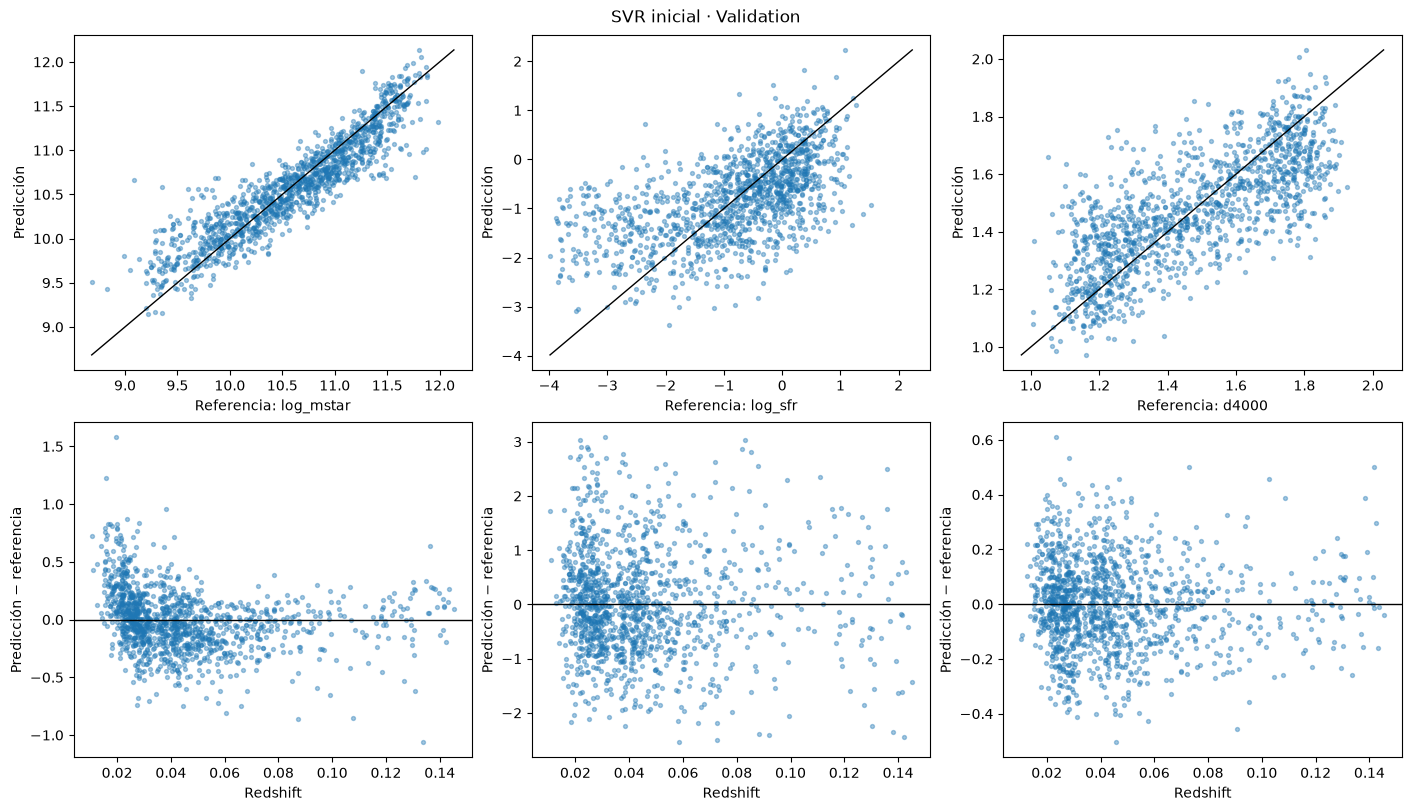

In [10]:
PREDICCIONES_SVR = {}
METRICAS_SVR = []
for particion in ['Train', 'Validation']:
    pred = predecir_svr(PAQUETE_SVR, X[particion])
    datos, met = evaluar_predicciones(TABLAS[particion], pred, 'SVR_RGB_ImageNet_PCA_z', STATS_AG['y_std'])
    PREDICCIONES_SVR[particion] = datos
    METRICAS_SVR.append(met)
    escribir_csv(datos, SALIDA_SVR / f'predicciones_{particion}.csv')
    escribir_csv(met, SALIDA_SVR / f'metricas_{particion}.csv')
METRICAS_SVR = pd.concat(METRICAS_SVR, ignore_index=True)
display(METRICAS_SVR[['particion', 'objetivo', 'n', 'MAE', 'RMSE', 'sesgo', 'R2', 'MSE_normalizado']])
CRITERIO_SVR = float(METRICAS_SVR.loc[METRICAS_SVR.particion.eq('Validation'), 'MSE_normalizado'].mean())
REGISTRO_SVR = dict(modelo='SVR_RGB_ImageNet_PCA_z', etapa='Candidato inicial, sin búsqueda de hiperparámetros',
                    criterio='Promedio de MSE normalizado de las tres propiedades en Validation',
                    valor_validation=CRITERIO_SVR, identidad=IDENTIDAD_SVR,
                    modelo_sha256=sha_archivo(SALIDA_SVR / 'modelo_svr_inicial.joblib'),
                    semillas_pca=[CFG_SVR['semilla']], ensamble=False, test_consultado_en_AG=True)
registro_path = SALIDA_SVR / 'registro_candidato_svr.json'
if (SALIDA_SVR / 'test_abierto_svr.json').exists() and registro_path.exists():
    anterior = json.loads(registro_path.read_text())
    if anterior != REGISTRO_SVR:
        raise RuntimeError('Cambió el candidato después de abrir Test.')
escribir_json(REGISTRO_SVR, registro_path)
print('Criterio global en Validation:', f'{CRITERIO_SVR:.6f}')
diagnosticar(PREDICCIONES_SVR['Validation'], TABLAS['Train'], SALIDA_SVR)


## 7 · Comparación con el candidato neuronal A–G

Recuperamos la corrida individual que quedó seleccionada en A–G y verificamos sus predicciones sobre los mismos ID de Validation. En el archivo de referencia corresponde a E con semilla 42. Recalculamos sus métricas con las etiquetas y escalas comunes, en lugar de copiar valores numéricos del reporte.

Contrastamos un SVR de configuración fija con una CNN cuya configuración fue seleccionada entre A–G. Además, el SVR utiliza RGB y un extractor ImageNet congelado, mientras que E utiliza GRZ y un extractor ajustado al problema. Registramos estas diferencias para no atribuir una ventaja únicamente al algoritmo de regresión ni presentar ambos presupuestos de selección como idénticos. El análisis nos permite valorar dos sistemas disponibles, pero no sustituye un experimento controlado con el mismo extractor ni la comparación final entre seis algoritmos.


In [11]:
def comparar_con_ag(raiz, tabla_val, met_svr, stats, destino):
    raiz = Path(raiz)
    necesarias = [raiz / 'seleccion_cerrada.json', raiz / 'fuentes_comparacion_A_G.json']
    if not all(p.is_file() for p in necesarias):
        print('SVR ya está evaluado. Falta seleccion_cerrada.json o fuentes_comparacion_A_G.json para contrastarlo con A–G.')
        return pd.DataFrame(), pd.DataFrame()
    sel = json.loads(necesarias[0].read_text())
    fuentes = json.loads(necesarias[1].read_text())
    elegidas = [f for f in fuentes if f['variante'] == sel['variante'] and int(f['semilla']) == int(sel['semilla'])]
    if len(elegidas) != 1:
        raise ValueError('No hay una fuente única de predicciones para la corrida seleccionada de A–G.')
    ruta = resolver_ruta_ag(elegidas[0]['archivo'], raiz)
    if sha_archivo(ruta) != elegidas[0]['sha256']:
        raise ValueError('Cambió el archivo de predicciones de A–G.')
    ag = pd.read_csv(ruta, dtype={'mangaid': str})
    if (ag.mangaid.duplicated().any() or set(ag.mangaid) != set(tabla_val.mangaid)
            or not ag.particion.eq('Validation').all()
            or not ag.variante.eq(sel['variante']).all()
            or not ag.semilla.eq(sel['semilla']).all()):
        raise ValueError('Las predicciones A–G no corresponden a la selección y muestra esperadas.')
    ag = ag.set_index('mangaid').loc[tabla_val.mangaid].reset_index()
    if not np.allclose(ag[OBJETIVOS], tabla_val[OBJETIVOS], atol=1e-6, rtol=0):
        raise ValueError('Las etiquetas de ambos modelos no coinciden.')
    pred = ag[['pred_' + y for y in OBJETIVOS]].to_numpy()
    _, met_ag = evaluar_predicciones(tabla_val, pred, sel['variante'] + '_s' + str(sel['semilla']), stats['y_std'])
    met_svr = met_svr.loc[met_svr.particion.eq('Validation')].copy()
    juntas = pd.concat([met_ag, met_svr], ignore_index=True)
    ranking = (juntas.groupby('modelo', as_index=False).MSE_normalizado.mean()
               .sort_values('MSE_normalizado').reset_index(drop=True))
    escribir_csv(juntas, Path(destino) / 'comparacion_AG_SVR_Validation.csv')
    escribir_csv(ranking, Path(destino) / 'comparacion_global_AG_SVR_Validation.csv')
    return juntas, ranking


In [12]:
COMPARACION, RANKING_DOS = comparar_con_ag(CARPETA_AG, TABLAS['Validation'], METRICAS_SVR,
                                         STATS_AG, SALIDA_SVR)
if not COMPARACION.empty:
    display(COMPARACION[['modelo', 'objetivo', 'MAE', 'RMSE', 'R2', 'MSE_normalizado']])
    display(RANKING_DOS)
    print('Comparación de sistemas completos: el extractor y la representación también difieren.')
    print('Esta tabla no sustituye la comparación pendiente entre los seis algoritmos.')


,modelo,objetivo,MAE,RMSE,R2,MSE_normalizado
0,E_multi_grz_z_huber_s42,log_mstar,0.082898,0.108829,0.972454,0.028323
1,E_multi_grz_z_huber_s42,log_sfr,0.394586,0.597520,0.736249,0.264746
2,E_multi_grz_z_huber_s42,d4000,0.052342,0.073037,0.903949,0.090568
3,SVR_RGB_ImageNet_PCA_z,log_mstar,0.199477,0.266115,0.835294,0.169351
4,SVR_RGB_ImageNet_PCA_z,log_sfr,0.759899,0.982788,0.286476,0.716217
5,SVR_RGB_ImageNet_PCA_z,d4000,0.125858,0.161113,0.532613,0.440704


,modelo,MSE_normalizado
0,E_multi_grz_z_huber_s42,0.127879
1,SVR_RGB_ImageNet_PCA_z,0.442091


Comparación de sistemas completos: el extractor y la representación también difieren.
Esta tabla no sustituye la comparación pendiente entre los seis algoritmos.


## 8 · Resultado del candidato inicial

Generamos el siguiente texto a partir de las métricas de esta ejecución. El resumen identifica la representación, las unidades y la puntuación global, y conserva el alcance de la comparación. Solo describimos un mejor rendimiento cuando contamos con las predicciones verificadas de ambos candidatos. No anticipamos que SVR superará a la CNN.


In [13]:
def tabla_markdown(tabla, columnas):
    lineas = ['| ' + ' | '.join(columnas) + ' |', '| ' + ' | '.join(['---'] * len(columnas)) + ' |']
    for _, fila in tabla[columnas].iterrows():
        valores = [f'{v:.6f}' if isinstance(v, (float, np.floating)) else str(v) for v in fila]
        lineas.append('| ' + ' | '.join(valores) + ' |')
    return '\n'.join(lineas)

val = METRICAS_SVR.loc[METRICAS_SVR.particion.eq('Validation')]
lineas = [
    'Resultado del segundo candidato: SVR', '',
    f'Entrenamos un SVR por propiedad con las {len(TABLAS["Train"]):,} galaxias de Train '
    f'y evaluamos las mismas {len(TABLAS["Validation"]):,} galaxias de Validation de A–G.', '',
    'Utilizamos RGB de A–G, un extractor ImageNet fijo, PCA ajustado con Train y redshift. '
    'Los tres regresores predicen propiedades diferentes; no combinamos sus salidas en un ensamble.', '',
    tabla_markdown(val, ['objetivo', 'MAE', 'RMSE', 'sesgo', 'R2', 'MSE_normalizado']), '',
    f'Obtuvimos un MSE normalizado global de Validation de {CRITERIO_SVR:.6f}. '
    'Los errores de masa y SFR están en dex; los de D4000 son adimensionales.', '',
]
if not RANKING_DOS.empty:
    lineas.extend(['Comparación con la corrida individual seleccionada de A–G:', '',
                   tabla_markdown(RANKING_DOS, ['modelo', 'MSE_normalizado']), '',
                   'El menor valor corresponde a ' + str(RANKING_DOS.iloc[0]['modelo'])
                   + '. Esta comparación incluye cambios de representación y entrenamiento del extractor; '
                   'no aísla exclusivamente el algoritmo de regresión.', ''])
lineas.extend(['Documentamos esta configuración como el candidato inicial de SVR. '
               'Todavía no seleccionamos los dos mejores entre seis algoritmos ni declaramos el modelo final del proyecto. '
               'Si SVR queda entre esos dos candidatos, realizaremos su ajuste de hiperparámetros en una etapa posterior.', ''])
RESUMEN_SVR = '\n'.join(lineas)
(SALIDA_SVR / 'resumen_SVR.md').write_text(RESUMEN_SVR, encoding='utf-8')
display(Markdown(RESUMEN_SVR))


Resultado del segundo candidato: SVR

Entrenamos un SVR por propiedad con las 7,121 galaxias de Train y evaluamos las mismas 1,261 galaxias de Validation de A–G.

Utilizamos RGB de A–G, un extractor ImageNet fijo, PCA ajustado con Train y redshift. Los tres regresores predicen propiedades diferentes; no combinamos sus salidas en un ensamble.

| objetivo | MAE | RMSE | sesgo | R2 | MSE_normalizado |
| --- | --- | --- | --- | --- | --- |
| log_mstar | 0.199477 | 0.266115 | -0.004865 | 0.835294 | 0.169351 |
| log_sfr | 0.759899 | 0.982788 | 0.034490 | 0.286476 | 0.716217 |
| d4000 | 0.125858 | 0.161113 | -0.001860 | 0.532613 | 0.440704 |

Obtuvimos un MSE normalizado global de Validation de 0.442091. Los errores de masa y SFR están en dex; los de D4000 son adimensionales.

Comparación con la corrida individual seleccionada de A–G:

| modelo | MSE_normalizado |
| --- | --- |
| E_multi_grz_z_huber_s42 | 0.127879 |
| SVR_RGB_ImageNet_PCA_z | 0.442091 |

El menor valor corresponde a E_multi_grz_z_huber_s42. Esta comparación incluye cambios de representación y entrenamiento del extractor; no aísla exclusivamente el algoritmo de regresión.

Documentamos esta configuración como el candidato inicial de SVR. Todavía no seleccionamos los dos mejores entre seis algoritmos ni declaramos el modelo final del proyecto. Si SVR queda entre esos dos candidatos, realizaremos su ajuste de hiperparámetros en una etapa posterior.


## 9 · Test opcional, después de cerrar las decisiones de desarrollo

Mantenemos esta sección desactivada por defecto. Mientras construimos los seis candidatos y ajustamos los dos mejores, utilizamos los datos de desarrollo para decidir. Cuando corresponda realizar la evaluación descriptiva final, cambiamos `evaluar_test` a `True` y ejecutamos esta sección con el candidato registrado. Esta opción no modifica su firma científica ni obliga a entrenarlo de nuevo.

Antes de predecir verificamos que el archivo del modelo coincida con el que registramos después de Validation. Después extraemos las características de Test, aplicamos las transformaciones ya ajustadas y calculamos las métricas sin actualizar ningún parámetro.

Reconocemos que estas 917 galaxias de Test ya fueron consultadas durante A–G. Aunque no las utilizamos para ajustar SVR, su reutilización pertenece a la continuidad exploratoria del proyecto y no constituye una confirmación externa nunca observada.


In [14]:
if not CFG_SVR['evaluar_test']:
    print('No evaluamos Test: estamos construyendo los candidatos iniciales.')
else:
    modelo_path = SALIDA_SVR / 'modelo_svr_inicial.joblib'
    registro = json.loads((SALIDA_SVR / 'registro_candidato_svr.json').read_text())
    if registro['identidad'] != IDENTIDAD_SVR or registro['modelo_sha256'] != sha_archivo(modelo_path):
        raise ValueError('El modelo no coincide con el candidato registrado antes de Test.')
    marca = dict(identidad=IDENTIDAD_SVR, modelo_sha256=registro['modelo_sha256'],
                 test_ids_sha256=firma(TABLAS['Test'].mangaid.tolist()),
                 alcance='Descriptivo: Test fue consultado previamente en A–G')
    marca_path = SALIDA_SVR / 'test_abierto_svr.json'
    if marca_path.exists() and json.loads(marca_path.read_text()) != marca:
        raise ValueError('El modelo o las galaxias cambiaron después de abrir Test.')
    escribir_json(marca, marca_path)
    paquete_test = recuperar_modelo(modelo_path, IDENTIDAD_SVR)
    f_test = extraer_caracteristicas(TABLAS['Test'], EXTRACTOR, DISPOSITIVO,
                                     ESPECIFICACION_EXTRACTOR, CFG_SVR, CACHE_CARACTERISTICAS / 'Test')
    x_test = matriz_entrada(f_test, TABLAS['Test'])
    datos_test, met_test = evaluar_predicciones(TABLAS['Test'], predecir_svr(paquete_test, x_test),
                                               'SVR_RGB_ImageNet_PCA_z', STATS_AG['y_std'])
    escribir_csv(datos_test, SALIDA_SVR / 'predicciones_Test.csv')
    escribir_csv(met_test, SALIDA_SVR / 'metricas_Test.csv')
    display(met_test)
    diagnosticar(datos_test, TABLAS['Train'], SALIDA_SVR)
    print('Evaluación descriptiva de Test; no modificamos la configuración ni elegimos hiperparámetros con ella.')


No evaluamos Test: estamos construyendo los candidatos iniciales.


## 10 · Conservación de los resultados

Guardamos `modelo_svr_inicial.joblib`, el preprocesamiento y los tres regresores en la carpeta identificada por la configuración del experimento. El paquete final permite predecir desde vectores de 2048 características y redshift mediante `predecir_svr`; para nuevas imágenes debemos reproducir primero la misma composición RGB, normalización y extractor ImageNet.

El ZIP de resultados reúne las tablas, predicciones, diagnóstico, protocolo y resumen.


In [15]:
ZIP_SVR = SALIDA_SVR / 'resultados_SVR_inicial.zip'
with zipfile.ZipFile(ZIP_SVR, 'w', compression=zipfile.ZIP_DEFLATED) as archivo_zip:
    for ruta in sorted(SALIDA_SVR.rglob('*')):
        if ruta.is_file() and ruta.suffix.lower() in {'.csv', '.json', '.pdf', '.md'}:
            archivo_zip.write(ruta, ruta.relative_to(SALIDA_SVR))
print('Resultados:', ZIP_SVR)
print('Modelo y preprocesamiento:', SALIDA_SVR / 'modelo_svr_inicial.joblib')
print('Las características están en:', CACHE_CARACTERISTICAS)
try:
    display(FileLink(os.path.relpath(ZIP_SVR, Path.cwd())))
except ValueError:
    pass


Resultados: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/74b206b7ef8e6666/resultados_SVR_inicial.zip
Modelo y preprocesamiento: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/74b206b7ef8e6666/modelo_svr_inicial.joblib
Las características están en: /home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/_caracteristicas/a6fd9f6ac3bd1504


/home/a01796921/DESI_experimentos_svr/modelo_02_svr_v01/74b206b7ef8e6666/resultados_SVR_inicial.zip

11 · Alcance y siguiente etapa

Con este notebook dejamos preparado un segundo candidato y un procedimiento reproducible de evaluación. El método de regresión es SVR y su representación visual procede de un extractor fijo.

Si el candidato queda entre los dos mejores al completar la comparación requerida, podemos explorar después C, epsilon, gamma y el número de componentes de PCA. Por ejemplo, 64, 128 y 256 componentes; C de 1, 10 y 100; y epsilon de 0.05, 0.1 y 0.2 son opciones para diseñar esa búsqueda. Estos son candidatos futuros, no valores que hayamos probado en este archivo. Cualquier validación cruzada posterior deberá volver a ajustar escalas y PCA dentro de cada pliegue de entrenamiento.

Referencias de implementación

- Scikit-learn. [SVR](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html). Kernel, C, epsilon, gamma y costo computacional.
- Scikit-learn. [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html). Reducción de dimensión y solucionador aleatorizado.
- Scikit-learn. [Prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html). Ajuste del preprocesamiento exclusivamente con entrenamiento.
- Torchvision 0.23. [ResNet50](https://docs.pytorch.org/vision/0.23/models/generated/torchvision.models.resnet50.html). Pesos ImageNet1K V1 y normalización RGB.

Este notebook se entrega sin resultados de entrenamiento sobre las galaxias: los archivos de imágenes y el entorno GPU se encuentran en el servidor del proyecto. Al ejecutarlo allí, las métricas y el resumen se generan a partir de sus datos.
